# E1 i vectors on the matched 2000 clip pilot

Audio → MFCC and delta frames → Gaussian UBM → total variability model →
16-dimensional length-normalized i-vector → logistic regression accent head.

This is a small, genuine i-vector teaching pipeline: eight diagonal Gaussian
components, at most 30,000 sampled UBM frames, and five total-variability iterations.
The frame scaler, UBM, and total-variability matrix are learned from the **1,280
training clips only**, without accent labels, and remain fixed thereafter. Labels
enter the LR head. This conservative fit scope keeps validation and test speakers
out of extractor training. All 2,000 clips are retained, including validation and test.
Use the **Singlish final fusion (Python 3.14)** kernel; no package installation runs here.

In [1]:
from pathlib import Path
import sys, json, hashlib, inspect
import joblib
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display

working = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [working, *working.parents]
                    if (p / 'notebooks/experiment_common.py').exists() and (p / 'data').is_dir())
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
config = common.configure(PROJECT_ROOT, PROJECT_ROOT / 'data/e1_audio_1000x2/data')
RANDOM_SEED = common.SEED
SAMPLE_RATE = common.SAMPLE_RATE
MAX_SECONDS = common.MAX_SECONDS
MODEL_KEY = 'e1_ivector'
OUTPUT_DIR = config['output'] / MODEL_KEY
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(json.dumps(common.environment(), indent=2))

{
  "python": "3.14.7",
  "packages": {
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "librosa": "1.0.0",
    "torch": "2.14.0",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 1 Reuse the exact pilot manifest and saved speaker split

In [2]:
frame, fingerprint = common.prepare_manifest(config)
assert len(frame) == 2000 and frame.groupby('label').size().to_dict() == {0: 1000, 1: 1000}
split = common.shared_split(config, frame, fingerprint)
train_idx, val_idx, test_idx = [split[name] for name in ['train', 'validation', 'test']]
trainval_idx = np.sort(np.r_[train_idx, val_idx])
labels = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
assert [len(train_idx), len(val_idx), len(test_idx)] == [1280, 320, 400]
# Hashes, clip IDs, speaker IDs, labels, and row order are identical to the earlier pilot.
preparation_sha256 = hashlib.sha256(inspect.getsource(common.prepare_audio).encode()).hexdigest()
print('Shared preparation SHA256:', preparation_sha256)

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb
{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.
Shared preparation SHA256: cee82f490ec24817ffdce8d1393b1e83fc550f85727cd6fa11c1908402f97fc1


## 2 Prepare the same audio and retain MFCC frames

Use the original pilot's shared mono 16 kHz preparation, 30 dB silence trim,
peak normalization before the six-second cap, and one-second minimum padding.
The i-vector frontend then computes 13 MFCCs and 13 deltas using 25 ms windows
and 10 ms hops, and discards low-energy frames. These model-specific frame
features differ from the 39 summary features. Any failed clip stops the run;
it is never silently removed from the matched dataset.

In [3]:
N_MFCC, N_FFT, HOP_LENGTH = 13, 400, 160
frame_sets = []
for number, path in enumerate(frame.path, 1):
    waveform, real_samples = common.prepare_audio(Path(path))
    mfcc = librosa.feature.mfcc(y=waveform, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                n_fft=N_FFT, hop_length=HOP_LENGTH)
    delta = librosa.feature.delta(mfcc)
    rms = librosa.feature.rms(y=waveform, frame_length=N_FFT, hop_length=HOP_LENGTH).ravel()
    keep = rms[:mfcc.shape[1]] > max(float(np.max(rms)) * .03, 1e-5)
    features = np.vstack([mfcc, delta]).T[keep].astype(np.float64)
    if len(features) < 20 or not np.isfinite(features).all():
        raise ValueError(f'Invalid frames for {path}; preserve the matched clip list')
    frame_sets.append(features)
    if number % 200 == 0:
        print(f'MFCC frames: {number}/{len(frame)}', flush=True)
assert len(frame_sets) == 2000

/home/mh/miniconda3/envs/singlish-py314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MFCC frames: 200/2000


MFCC frames: 400/2000


MFCC frames: 600/2000


MFCC frames: 800/2000


...

MFCC frames: 1200/2000


MFCC frames: 1400/2000


MFCC frames: 1600/2000


MFCC frames: 1800/2000


MFCC frames: 2000/2000


## 3 Fit the frame scaler and UBM on training speech only

In [4]:
from sklearn.mixture import GaussianMixture
rng = np.random.default_rng(RANDOM_SEED)
N_COMPONENTS = 8
MAX_UBM_FRAMES = 30_000

training_frames = np.concatenate([frame_sets[i] for i in train_idx], axis=0)
chosen = rng.choice(len(training_frames), size=min(MAX_UBM_FRAMES, len(training_frames)), replace=False)
ubm_frames = training_frames[chosen]
frame_scaler = StandardScaler().fit(ubm_frames)
ubm = GaussianMixture(n_components=N_COMPONENTS, covariance_type='diag',
                      reg_covar=1e-3, max_iter=100, random_state=RANDOM_SEED)
ubm.fit(frame_scaler.transform(ubm_frames))
print('UBM fitted on', len(ubm_frames), 'training frames')
print('Converged:', ubm.converged_)

UBM fitted on 30000 training frames
Converged: True


## 4 Collect sufficient statistics with the fixed training UBM

In [5]:
def ubm_statistics(frames):
    scaled = frame_scaler.transform(frames)
    responsibilities = ubm.predict_proba(scaled)  # frames × components
    n = responsibilities.sum(axis=0)
    f = responsibilities.T @ scaled - n[:, None] * ubm.means_
    return n, f

stats = [ubm_statistics(frames) for frames in frame_sets]
print('N shape:', stats[0][0].shape, '| F shape:', stats[0][1].shape)

N shape: (8,) | F shape: (8, 26)


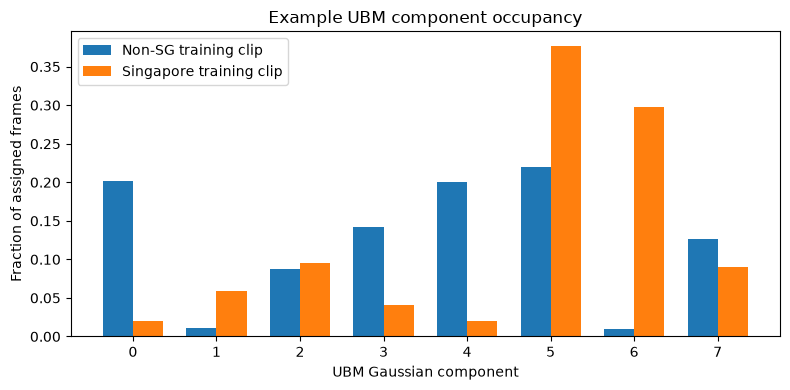

In [6]:
component_ids = np.arange(N_COMPONENTS)
fig, ax = plt.subplots(figsize=(8, 4))
for label, offset, color, name in [(0, -0.18, 'tab:blue', 'Non-SG'),
                                   (1,  0.18, 'tab:orange', 'Singapore')]:
    example = next(int(i) for i in train_idx if labels[i] == label)
    counts = stats[example][0]
    ax.bar(component_ids + offset, counts / counts.sum(), width=0.36,
           color=color, label=f'{name} training clip')
ax.set(xticks=component_ids, xlabel='UBM Gaussian component',
       ylabel='Fraction of assigned frames', title='Example UBM component occupancy')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'ivector_ubm_occupancy.png', dpi=150)
plt.show()

## 5 Learn total variability and extract i vectors

Only training indices enter the total-variability EM updates. Validation and test
statistics are transformed using this fixed extractor; they never update it.

In [7]:
IVECTOR_DIM = 16
TV_ITERATIONS = 5
TV_REGULARIZATION = 1e-3
C, D = ubm.means_.shape
variances = ubm.covariances_  # diagonal Gaussian variances, C × D
T = rng.normal(0, 0.05, size=(C, D, IVECTOR_DIM))
identity = np.eye(IVECTOR_DIM)

def posterior(n, f, T_matrix):
    # L = I + sum_c N_c T_c^T Sigma_c^-1 T_c
    weighted_T = T_matrix / variances[:, :, None]
    precision = identity + np.einsum('c,cdr,cds->rs', n, T_matrix, weighted_T)
    covariance = np.linalg.inv(precision)
    # b = sum_c T_c^T Sigma_c^-1 F_c
    linear_term = np.einsum('cdr,cd->r', weighted_T, f)
    mean = covariance @ linear_term
    second_moment = covariance + np.outer(mean, mean)
    return mean, second_moment

for iteration in range(TV_ITERATIONS):
    numerator = np.zeros_like(T)                 # sum F_c E[w]^T
    denominator = np.zeros((C, IVECTOR_DIM, IVECTOR_DIM))  # sum N_c E[ww^T]
    for i in train_idx:
        n, f = stats[i]
        mean, second = posterior(n, f, T)
        numerator += f[:, :, None] * mean[None, None, :]
        denominator += n[:, None, None] * second[None, :, :]
    for component in range(C):
        T[component] = np.linalg.solve(
            denominator[component] + TV_REGULARIZATION * identity,
            numerator[component].T,
        ).T
    print(f'Total-variability iteration {iteration + 1}/{TV_ITERATIONS}')

def extract_ivector(n, f):
    vector, _ = posterior(n, f, T)
    norm = np.linalg.norm(vector)
    return vector / norm if norm > 1e-12 else vector

X = np.vstack([extract_ivector(n, f) for n, f in stats])
assert X.shape == (len(frame_sets), IVECTOR_DIM) and np.isfinite(X).all()
print('i-vector matrix:', X.shape, '(clips × dimensions)')

joblib.dump({'frame_scaler': frame_scaler, 'ubm': ubm, 'T': T,
    'fit_clip_ids': frame.clip_id.iloc[train_idx].tolist(),
    'dataset_fingerprint': fingerprint, 'preparation_sha256': preparation_sha256},
    OUTPUT_DIR / 'extractor.joblib')
representation = {'type': 'i-vector', 'dimension': IVECTOR_DIM,
    'ubm_components': N_COMPONENTS, 'ubm_frames': len(ubm_frames),
    'tv_iterations': TV_ITERATIONS, 'extractor_fit_partition': 'train',
    'extractor_fit_clips': len(train_idx), 'extractor_fit_speakers': len(set(groups[train_idx])),
    'length_normalized': True, 'mfcc': 13, 'delta': 13, 'n_fft': N_FFT, 'hop_length': HOP_LENGTH}

Total-variability iteration 1/5
Total-variability iteration 2/5


Total-variability iteration 3/5
Total-variability iteration 4/5


Total-variability iteration 5/5


i-vector matrix: (2000, 16) (clips × dimensions)


## 6 Inspect the representation using training fitted PCA

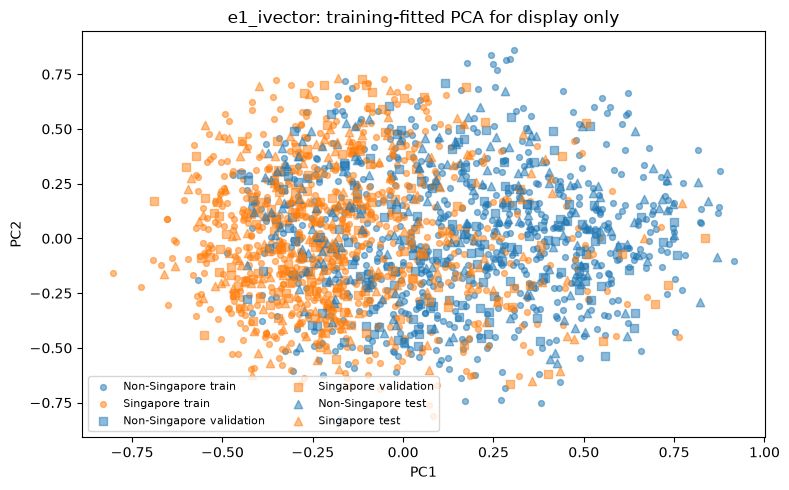

In [8]:
from sklearn.decomposition import PCA
projection = PCA(n_components=2, random_state=RANDOM_SEED).fit(X[train_idx])
points = projection.transform(X)
fig, ax = plt.subplots(figsize=(8, 5))
for part, marker in [('train', 'o'), ('validation', 's'), ('test', '^')]:
    for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
        idx = split[part][labels[split[part]] == label]
        ax.scatter(points[idx, 0], points[idx, 1], c=color, marker=marker, alpha=.5,
                   s=18 if part == 'train' else 36, label=f'{common.CLASS_NAMES[label]} {part}')
ax.set(title=MODEL_KEY + ': training-fitted PCA for display only', xlabel='PC1', ylabel='PC2')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'embedding_pca.png', dpi=150)
plt.show()
plt.close(fig)

## 7 Select the LR head using validation only

In [9]:
candidates = [
    (f'C={c:g}', Pipeline([
        ('scale', StandardScaler()),
        ('classifier', LogisticRegression(C=c, class_weight='balanced', max_iter=5000,
                                          random_state=RANDOM_SEED)),
    ])) for c in [0.01, 0.1, 1.0, 10.0, 100.0]
]
selected_model, validation = common.choose_candidate(candidates, X, labels, split)
common.write_json(OUTPUT_DIR / 'validation_selection.json', validation)

candidate  macro_f1  balanced_accuracy
   C=0.01  0.837494           0.837500
    C=0.1  0.849977           0.850000
      C=1  0.853112           0.853125
     C=10  0.853112           0.853125
    C=100  0.849977           0.850000
Validation choice: C=1


## 8 Refit the head on development and score the shared test

{
  "accuracy": 0.86,
  "macro_f1": 0.8599439775910365,
  "balanced_accuracy": 0.86,
  "roc_auc": 0.9457,
  "errors": 56,
  "confusion_matrix": [
    [
      168,
      32
    ],
    [
      24,
      176
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.09294563364022851,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.8120295844048764,
      0.9047705943691344
    ],
    "balanced_accuracy": [
      0.8118115493778711,
      0.9047704703988284
    ],
    "macro_f1": [
      0.8113664787839027,
      0.904696118951462
    ]
  }
}


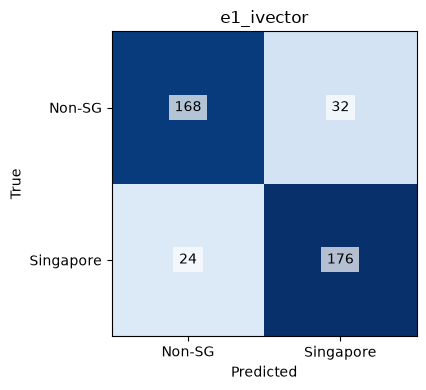

,clip_id,path,group,label,prediction,score_class_1,error
0,non_singapore/speaker_043/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_043,0,1,0.545899,True
1,non_singapore/speaker_073/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_073,0,1,0.901372,True
2,non_singapore/speaker_089/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_089,0,1,0.527888,True
3,non_singapore/speaker_093/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_093,0,1,0.619448,True
4,non_singapore/speaker_093/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_093,0,1,0.620861,True
5,non_singapore/speaker_150/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_150,0,1,0.952499,True
6,non_singapore/speaker_150/clip_002.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_150,0,1,0.871696,True
7,non_singapore/speaker_150/clip_003.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_150,0,1,0.848871,True
8,non_singapore/speaker_150/clip_004.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_150,0,1,0.826890,True
9,non_singapore/speaker_162/clip_001.wav,/home/mh/nusproj/singlish-whisper/data/e1_audi...,non_singapore::speaker_162,0,1,0.582611,True


In [10]:
# Keep the representation fixed; refit the selected scaler and LR head on development.
classifier = clone(selected_model).fit(X[trainval_idx], labels[trainval_idx])
predictions = classifier.predict(X[test_idx])
probabilities = classifier.predict_proba(X[test_idx])[:, 1]
report = common.save_result(config, MODEL_KEY, frame, fingerprint, split, classifier,
    predictions, probabilities, validation, probability=True,
    extra={'representation': representation, 'features': int(X.shape[1]),
           'preparation_sha256': preparation_sha256,
           'training': 'Representation fixed before validation; selected scaler and LR refit on train plus validation',
           'comparison': 'Retrospective extension of the existing 2000-clip pilot; test has been inspected before'})
np.savez_compressed(OUTPUT_DIR / 'features_and_split.npz', X=X,
    clip_ids=frame.clip_id.to_numpy(dtype=str), paths=frame.path.to_numpy(dtype=str),
    labels=labels, groups=groups, fingerprint=np.array(fingerprint), **split)
display(pd.read_csv(OUTPUT_DIR / 'test_errors.csv'))

## Interpretation and limits

These results now use the same 2,000 files, audio preparation, speaker partitions,
and 400 held-out clips as the original matched pilot. The saved per-clip predictions
support paired comparisons. The earlier 200-clip demonstration is backed up separately;
its 40-test-clip score is not this result.

The shared LR search selects validation macro F1, then balanced accuracy, then the
first candidate (smaller C) on an exact tie, matching the original pilot's LR heads.
Only the selected scaler and accent head are refitted on the 1,600 development clips.
The test does not select settings. This extends an already inspected test retrospectively;
it is not a new untouched test or full cross-validation. Speaker bootstrap intervals
condition on this fitted model and split and exclude training and selection uncertainty.

Class and source remain linked: Singapore is MNSC and non-Singapore is Common Voice.
Speaker separation does not remove microphone, prompt, or corpus differences.
Different representations are intentional experimental differences, so results compare
complete pipelines rather than isolate architecture alone. Logistic regression's
probabilities are not explicitly calibrated. Do not claim an independent generalization
gain from a close pilot ranking.

## Recorded matched pilot result

Test BA: **86.00%**; macro F1: **0.8599**; errors: **56/400**. Validation selected **C=1**. All 2,000 clip identities and the shared 1,280/320/400 speaker split verified.

Results: `../outputs/matched_2000_seed42/e1_ivector/`. Combined pilot: `../outputs/matched_2000_seed42/embedding_extension_report.md`.